# ERA V5 · Session 10 | A training loop that tells the truth
**Reproducible CPU baseline with GPU-aware MFU instrumentation.**\n
- Real causal language-model training, shape audit, numerical gradient check.
- Deliberately incorrect versus token-weighted gradient accumulation.
- Per-step loss and gradient-norm logging, a separately labeled diagnostic probe.
- Measured throughput, explicit MFU denominator policy, independently checked floating-point bits.

**Data scope:** fixed, handcrafted English sentences for a small-scale controlled experiment. No claims of real-world language-model quality.
**Determinism:** fixed seed, full precision for the baseline, dropout disabled, fixed scheduling and CPU thread count.

In [1]:
import os, math, time, struct, json, platform, copy
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
import numpy as np
import matplotlib.pyplot as plt

SEED = 20260829
CPU_THREADS = 2
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(CPU_THREADS)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')  # reference run: stable, deterministic, compatible with Colab CPU
print('PyTorch:', torch.__version__, '| device:', DEVICE, '| CPU threads:', torch.get_num_threads(), '| CUDA available:', torch.cuda.is_available())
print('Experiment type: measured CPU reference (not a GPU MFU benchmark).')

PyTorch: 2.10.0+cpu | device: cpu | CPU threads: 2 | CUDA available: False
Experiment type: measured CPU reference (not a GPU MFU benchmark).


## 1 · Data, shape vocabulary and actual causal transformer
- `B`: number of sequences in a micro-batch, `T`: padded time/token axis.
- `C`: hidden width; `H`: attention heads; `Dh=C/H`: head width; `V`: vocabulary size.
- This deliberately uses explicit attention so every intermediate tensor is visible.
- Padding is ignored in the **loss**. A causal upper-triangular mask prevents future-token access.

In [2]:
SHORT = [
  'we read books',
  'birds fly home',
  'water flows down',
  'stars shine tonight',
  'green trees grow',
  'the moon rises',
  'a dog sleeps',
  'rain falls softly',
]
LONG = [
  'the curious student reads a difficult book about mathematics and explains the solution to a friend',
  'the careful engineer tests every sensor before the spacecraft begins its long trip to another world',
  'the small computer learns simple patterns from examples and makes a prediction after each new token',
  'the patient teacher explains why a model can produce confident predictions while still being mistaken',
  'the research group measures how computation changes when a long sequence passes through self attention',
  'the quiet library contains many useful stories about scientific discoveries and forgotten mathematical ideas',
  'the software team investigates a failing test and records evidence before changing the running application',
  'the young astronomer studies distant galaxies through a telescope and carefully checks the observation notes',
]
TEXTS = SHORT + LONG
all_words = sorted(set(' '.join(TEXTS).split()))
itos = ['<pad>','<bos>','<eos>'] + all_words
stoi = {w:i for i,w in enumerate(itos)}
PAD = stoi['<pad>']
encoded = [torch.tensor([stoi['<bos>']] + [stoi[w] for w in s.split()] + [stoi['<eos>']], dtype=torch.long) for s in TEXTS]
V=len(itos); C=32; H=4; MAX_T=max(len(s) for s in encoded)
print(f'Corpus: {len(TEXTS)} documents ({len(SHORT)} short, {len(LONG)} long); vocabulary={V}, max tokens including BOS/EOS={MAX_T}.')

def collate(seqs):
    b=len(seqs); t=max(len(s) for s in seqs)
    x=torch.full((b,t), PAD, dtype=torch.long)
    for i,s in enumerate(seqs):x[i,:len(s)]=s
    return x

def shifted_loss(logits,tokens):
    # At time j, input prefix tokens[:j+1] predicts tokens[j+1].
    scores=logits[:,:-1,:].contiguous().reshape(-1, logits.shape[-1])
    target=tokens[:,1:].contiguous().reshape(-1)
    count=(target!=PAD).sum()
    total=F.cross_entropy(scores,target,ignore_index=PAD,reduction='sum')
    return total/count, total, int(count)

class TinyTransformer(nn.Module):
    def __init__(self, vocab, width=32, heads=4, max_t=32):
        super().__init__()
        assert width % heads == 0
        self.width,self.heads,self.head_size=width,heads,width//heads
        self.tok=nn.Embedding(vocab,width)
        self.pos=nn.Embedding(max_t,width)
        self.n1=nn.LayerNorm(width)
        self.qkv=nn.Linear(width,3*width,bias=False)
        self.proj=nn.Linear(width,width,bias=False)
        self.n2=nn.LayerNorm(width)
        self.ff1=nn.Linear(width,2*width)
        self.ff2=nn.Linear(2*width,width)
        self.out=nn.Linear(width,vocab,bias=False)
    def forward(self,tokens, trace=False):
        B,T=tokens.shape
        assert T <= self.pos.num_embeddings
        p=torch.arange(T,device=tokens.device)
        embed=self.tok(tokens)
        position=self.pos(p)
        hidden=embed+position
        norm=self.n1(hidden)
        joined=self.qkv(norm)
        q0,k0,v0=joined.chunk(3,dim=-1)
        q=q0.view(B,T,self.heads,self.head_size).transpose(1,2)
        k=k0.view(B,T,self.heads,self.head_size).transpose(1,2)
        v=v0.view(B,T,self.heads,self.head_size).transpose(1,2)
        scores=(q @ k.transpose(-2,-1))/math.sqrt(self.head_size)
        causal_mask=torch.triu(torch.ones(T,T,device=tokens.device,dtype=torch.bool),diagonal=1)
        scores=scores.masked_fill(causal_mask,float('-inf'))
        probs=F.softmax(scores,dim=-1)
        attended=probs@v
        concat=attended.transpose(1,2).contiguous().view(B,T,self.width)
        delta=self.proj(concat)
        residual=hidden+delta
        ff_input=self.n2(residual)
        ff_expanded=self.ff1(ff_input)
        ff_activated=F.gelu(ff_expanded)
        ff_projected=self.ff2(ff_activated)
        final_hidden=residual+ff_projected
        logits=self.out(final_hidden)
        if trace:
            shapes={'tokens [B,T]':tokens,'position indices [T]':p,'token embeddings [B,T,C]':embed,
                    'position embeddings [T,C]':position,'hidden [B,T,C]':hidden,'layernorm [B,T,C]':norm,
                    'qkv joint [B,T,3C]':joined,'Q [B,H,T,Dh]':q,'K [B,H,T,Dh]':k,'V [B,H,T,Dh]':v,
                    'attention scores [B,H,T,T]':scores,'causal mask [T,T]':causal_mask,'attention probabilities [B,H,T,T]':probs,
                    'context [B,H,T,Dh]':attended,'head concat [B,T,C]':concat,'attention output [B,T,C]':delta,
                    'residual [B,T,C]':residual,'FFN input [B,T,C]':ff_input,'FFN expanded [B,T,2C]':ff_expanded,
                    'FFN activated [B,T,2C]':ff_activated,'FFN projected [B,T,C]':ff_projected,
                    'final hidden [B,T,C]':final_hidden,'logits [B,T,V]':logits,
                    'shifted scores [B*(T-1),V]':logits[:,:-1].reshape(-1,logits.size(-1)),
                    'shifted targets [B*(T-1)]':tokens[:,1:].reshape(-1)}
            for name,value in shapes.items():print(f'{name:<41}: {tuple(value.shape)}')
        return logits

base=TinyTransformer(V,C,H,MAX_T)
short_batch=collate(encoded[:2]); long_batch=collate(encoded[len(SHORT):len(SHORT)+2])
print('Dimension legend: B=batch sequences; T=token slots; C=hidden width; H=head count; Dh=head width; V=vocabulary classes.')
_ = base(short_batch,trace=True)
print('Parameter/gradient tensor-shape audit:')
for name,p in base.named_parameters():print(f'  {name:<17} param {str(tuple(p.shape)):<14} grad (same shape after backward)')
print('All forward intermediate shapes and trainable parameter shapes printed above.')

Corpus: 16 documents (8 short, 8 long); vocabulary=120, max tokens including BOS/EOS=18.
Dimension legend: B=batch sequences; T=token slots; C=hidden width; H=head count; Dh=head width; V=vocabulary classes.
tokens [B,T]                             : (2, 5)
position indices [T]                     : (5,)
token embeddings [B,T,C]                 : (2, 5, 32)
position embeddings [T,C]                : (5, 32)
hidden [B,T,C]                           : (2, 5, 32)
layernorm [B,T,C]                        : (2, 5, 32)
qkv joint [B,T,3C]                       : (2, 5, 96)
Q [B,H,T,Dh]                             : (2, 4, 5, 8)
K [B,H,T,Dh]                             : (2, 4, 5, 8)
V [B,H,T,Dh]                             : (2, 4, 5, 8)
attention scores [B,H,T,T]               : (2, 4, 5, 5)
causal mask [T,T]                        : (5, 5)
attention probabilities [B,H,T,T]        : (2, 4, 5, 5)
context [B,H,T,Dh]                       : (2, 4, 5, 8)
head concat [B,T,C]                      

## 2 · Gradient check: manual central finite difference versus autograd
Select **one named scalar model weight**; keep inputs and all other weights fixed.
With `float64`, `eps=1e-5`, compare `dL/dw ≈ (L(w+eps)-L(w-eps))/(2 eps)` against backward.
No dropout or stochastic sampling appears in this check.

In [3]:
grad_model=copy.deepcopy(base).to(dtype=torch.float64).eval()
xcheck=short_batch.clone()
grad_model.zero_grad(set_to_none=True)
check_loss,_,_=shifted_loss(grad_model(xcheck),xcheck)
check_loss.backward()
param=grad_model.out.weight
row,col=1,1
analytical=param.grad[row,col].item()
original=param.data[row,col].item()
eps=1e-5
with torch.no_grad():
    param[row,col]=original+eps
    plus=shifted_loss(grad_model(xcheck),xcheck)[0].item()
    param[row,col]=original-eps
    minus=shifted_loss(grad_model(xcheck),xcheck)[0].item()
    param[row,col]=original
numeric=(plus-minus)/(2*eps)
abs_error=abs(analytical-numeric)
relative_error=abs_error/max(1e-12,abs(analytical),abs(numeric))
print(f'Checked weight: out.weight[{row},{col}]; original={original:.12f}; epsilon={eps:g}')
print(f'L(w+eps)={plus:.12f}; L(w-eps)={minus:.12f}')
print('Backpropagated gradient tensor shapes:')
for name,parameter in grad_model.named_parameters():
    print(f'  {name:<18} weight_shape={tuple(parameter.shape)}, grad_shape={tuple(parameter.grad.shape) if parameter.grad is not None else None}')
print('Loss tensor shape:',tuple(check_loss.shape),'(scalar); L(w+eps),L(w-eps) are scalar measurements')
print(f'Autograd: {analytical:+.12f} | finite difference: {numeric:+.12f} | absolute error: {abs_error:.3e} | relative error: {relative_error:.3e}')
assert abs_error<1e-7 and relative_error<1e-4, 'Derivative mismatch: inspect the weight or the finite-difference epsilon.'
print('PASS: numerical finite difference and backward agree to several decimal places.')

Checked weight: out.weight[1,1]; original=-0.155422955751; epsilon=1e-05
L(w+eps)=4.896831613880; L(w-eps)=4.896831628423
Backpropagated gradient tensor shapes:
  tok.weight         weight_shape=(120, 32), grad_shape=(120, 32)
  pos.weight         weight_shape=(18, 32), grad_shape=(18, 32)
  n1.weight          weight_shape=(32,), grad_shape=(32,)
  n1.bias            weight_shape=(32,), grad_shape=(32,)
  qkv.weight         weight_shape=(96, 32), grad_shape=(96, 32)
  proj.weight        weight_shape=(32, 32), grad_shape=(32, 32)
  n2.weight          weight_shape=(32,), grad_shape=(32,)
  n2.bias            weight_shape=(32,), grad_shape=(32,)
  ff1.weight         weight_shape=(64, 32), grad_shape=(64, 32)
  ff1.bias           weight_shape=(64,), grad_shape=(64,)
  ff2.weight         weight_shape=(32, 64), grad_shape=(32, 64)
  ff2.bias           weight_shape=(32,), grad_shape=(32,)
  out.weight         weight_shape=(120, 32), grad_shape=(120, 32)
Loss tensor shape: () (scalar); L(w+eps

## 3 · Gradient accumulation, with an intentionally incorrect implementation
Micro-batches have different counts of **valid targets**: short and long sentences.
Correct effective-batch objective: `(sum_i token_loss_sum_i)/(sum_i valid_targets_i)`.
Intentionally wrong objective: `(1/M) * sum_i (token_loss_sum_i / valid_targets_i)`.
The latter assigns equal importance to unequal micro-batches. Optimizer updates happen once per effective batch.

In [4]:
# Demonstrate mathematical agreement between full-batch and correctly accumulated gradients.
full=collate([encoded[0],encoded[1],encoded[8],encoded[9]])
ref=copy.deepcopy(base); correct=copy.deepcopy(base); bad=copy.deepcopy(base)
for m in (ref,correct,bad):m.zero_grad(set_to_none=True)
whole_loss,_,whole_count=shifted_loss(ref(full),full)
whole_loss.backward()
_,s_sum,s_count=shifted_loss(correct(short_batch),short_batch)
_,l_sum,l_count=shifted_loss(correct(long_batch),long_batch)
total_count=s_count+l_count
(s_sum/total_count).backward(); (l_sum/total_count).backward()
wrong_s,_,_=shifted_loss(bad(short_batch),short_batch)
wrong_l,_,_=shifted_loss(bad(long_batch),long_batch)
(wrong_s/2).backward();(wrong_l/2).backward()
refg=torch.cat([p.grad.flatten() for p in ref.parameters()]); cg=torch.cat([p.grad.flatten() for p in correct.parameters()]); bg=torch.cat([p.grad.flatten() for p in bad.parameters()])
correct_error=(refg-cg).abs().max().item()
wrong_error=(refg-bg).abs().max().item()
print(f'Contributing targets: short={s_count}, long={l_count}; correct weights={s_count/total_count:.3f}/{l_count/total_count:.3f}; wrong weights=0.5/0.5')
print(f'Max elementwise gradient error: single padded batch vs CORRECT accumulation: {correct_error:.3e}')
print(f'Max elementwise gradient error: single padded batch vs WRONG accumulation: {wrong_error:.3e}')
assert correct_error < 2e-6
assert wrong_error > 1e-5
print('PASS: token-weighted accumulation matches the full effective batch; equal micro-batch means do not.')

Contributing targets: short=8, long=34; correct weights=0.190/0.810; wrong weights=0.5/0.5
Max elementwise gradient error: single padded batch vs CORRECT accumulation: 3.725e-08
Max elementwise gradient error: single padded batch vs WRONG accumulation: 2.589e-01
PASS: token-weighted accumulation matches the full effective batch; equal micro-batch means do not.


## 4 · Actual training: identical initial model, schedule and optimizer
Train two separate model copies: corrected accumulation and deliberately broken average-of-averages.
Measure fixed-corpus post-update loss for both, and the **unclipped** gradient norm before every update.
We do *not* alter the initial weights or the sampled micro-batch schedule between runs.

step=01 valid=42 correct_loss=4.518225 wrong_loss=4.629433 grad_norm_correct=1.370566 grad_norm_wrong=1.839259
step=02 valid=42 correct_loss=4.064800 wrong_loss=4.396636 grad_norm_correct=1.343213 grad_norm_wrong=1.702909
step=03 valid=41 correct_loss=3.741628 wrong_loss=4.126605 grad_norm_correct=1.467705 grad_norm_wrong=2.237129
step=04 valid=40 correct_loss=3.441585 wrong_loss=3.839935 grad_norm_correct=1.648817 grad_norm_wrong=2.014762
step=05 valid=39 correct_loss=3.111773 wrong_loss=3.464065 grad_norm_correct=1.737229 grad_norm_wrong=2.048588
step=06 valid=39 correct_loss=2.820682 wrong_loss=3.188451 grad_norm_correct=1.717916 grad_norm_wrong=2.047793
step=07 valid=40 correct_loss=2.644042 wrong_loss=2.951226 grad_norm_correct=1.649128 grad_norm_wrong=2.909658
step=08 valid=42 correct_loss=2.295510 wrong_loss=2.593474 grad_norm_correct=1.821443 grad_norm_wrong=3.228927
step=09 valid=42 correct_loss=2.006797 wrong_loss=2.357320 grad_norm_correct=1.441978 grad_norm_wrong=2.212320
s

step=26 valid=39 correct_loss=0.403074 wrong_loss=0.553836 grad_norm_correct=1.114465 grad_norm_wrong=1.440068
step=27 valid=39 correct_loss=0.406560 wrong_loss=0.501762 grad_norm_correct=1.076819 grad_norm_wrong=1.257489


step=28 valid=40 correct_loss=0.399918 wrong_loss=0.444118 grad_norm_correct=1.040992 grad_norm_wrong=1.166395
step=29 valid=42 correct_loss=0.364007 wrong_loss=0.396127 grad_norm_correct=1.014447 grad_norm_wrong=1.023843


step=30 valid=42 correct_loss=0.338459 wrong_loss=0.370606 grad_norm_correct=0.704603 grad_norm_wrong=0.860024
step=31 valid=41 correct_loss=0.343447 wrong_loss=0.358910 grad_norm_correct=0.529004 grad_norm_wrong=0.854102


step=32 valid=40 correct_loss=0.362076 wrong_loss=0.363402 grad_norm_correct=0.499294 grad_norm_wrong=0.818179
step=33 valid=39 correct_loss=0.359956 wrong_loss=0.363951 grad_norm_correct=0.798315 grad_norm_wrong=1.074404
step=34 valid=39 correct_loss=0.330524 wrong_loss=0.351647 grad_norm_correct=1.062450 grad_norm_wrong=1.135705


step=35 valid=40 correct_loss=0.307864 wrong_loss=0.345293 grad_norm_correct=0.951166 grad_norm_wrong=0.955651
step=36 valid=42 correct_loss=0.313312 wrong_loss=0.343648 grad_norm_correct=0.523828 grad_norm_wrong=0.873276
step=37 valid=42 correct_loss=0.319467 wrong_loss=0.345123 grad_norm_correct=0.572776 grad_norm_wrong=0.797387
step=38 valid=41 correct_loss=0.321765 wrong_loss=0.347475 grad_norm_correct=0.584567 grad_norm_wrong=0.805388
step=39 valid=40 correct_loss=0.328031 wrong_loss=0.352991 grad_norm_correct=0.542378 grad_norm_wrong=0.829536
step=40 valid=39 correct_loss=0.338679 wrong_loss=0.354507 grad_norm_correct=0.549714 grad_norm_wrong=0.922283
step=41 valid=39 correct_loss=0.349618 wrong_loss=0.353045 grad_norm_correct=0.561507 grad_norm_wrong=0.917421
step=42 valid=40 correct_loss=0.328418 wrong_loss=0.343678 grad_norm_correct=0.905968 grad_norm_wrong=0.903267
step=43 valid=42 correct_loss=0.306970 wrong_loss=0.336815 grad_norm_correct=0.755897 grad_norm_wrong=0.855194
s

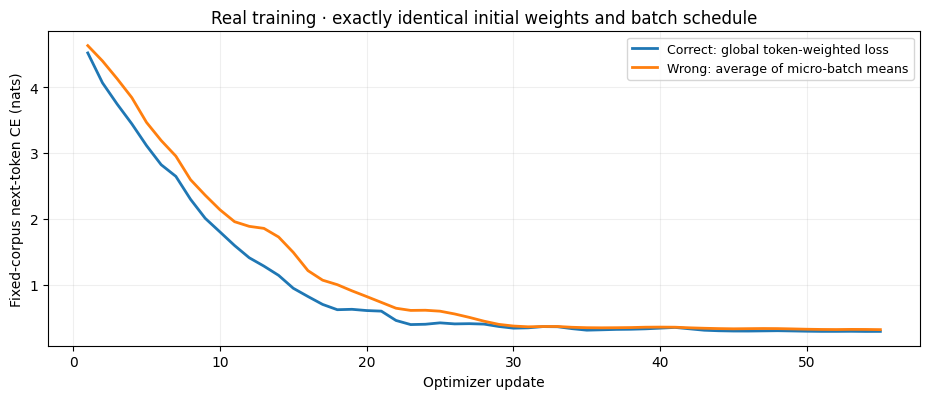

Final correct loss=0.289159; wrong loss=0.315906; difference=+0.026747
Optimizer state tensor shapes after real updates:
tok.weight {'step': (), 'exp_avg': (120, 32), 'exp_avg_sq': (120, 32)}
pos.weight {'step': (), 'exp_avg': (18, 32), 'exp_avg_sq': (18, 32)}
n1.weight {'step': (), 'exp_avg': (32,), 'exp_avg_sq': (32,)}
n1.bias {'step': (), 'exp_avg': (32,), 'exp_avg_sq': (32,)}
qkv.weight {'step': (), 'exp_avg': (96, 32), 'exp_avg_sq': (96, 32)}
proj.weight {'step': (), 'exp_avg': (32, 32), 'exp_avg_sq': (32, 32)}
n2.weight {'step': (), 'exp_avg': (32,), 'exp_avg_sq': (32,)}
n2.bias {'step': (), 'exp_avg': (32,), 'exp_avg_sq': (32,)}
ff1.weight {'step': (), 'exp_avg': (64, 32), 'exp_avg_sq': (64, 32)}
ff1.bias {'step': (), 'exp_avg': (64,), 'exp_avg_sq': (64,)}
ff2.weight {'step': (), 'exp_avg': (32, 64), 'exp_avg_sq': (32, 64)}
ff2.bias {'step': (), 'exp_avg': (32,), 'exp_avg_sq': (32,)}
out.weight {'step': (), 'exp_avg': (120, 32), 'exp_avg_sq': (120, 32)}


In [5]:
STEPS = 55
LR = 0.025
m_right=copy.deepcopy(base)
m_wrong=copy.deepcopy(base)
opt_right=torch.optim.AdamW(m_right.parameters(),lr=LR,weight_decay=0.0)
opt_wrong=torch.optim.AdamW(m_wrong.parameters(),lr=LR,weight_decay=0.0)
fixed_eval=collate(encoded)
steps_log=[]

def eval_loss(model):
    with torch.no_grad():return float(shifted_loss(model(fixed_eval),fixed_eval)[0])

def grad_l2(model):
    return float(torch.sqrt(sum((p.grad.detach().float().pow(2).sum() for p in model.parameters() if p.grad is not None), torch.tensor(0.0))))

for step in range(1,STEPS+1):
    # Rotate through all sentences, but always retain unequal target-count micro-batches.
    q=(step-1)%7
    s=collate([encoded[q],encoded[(q+1)%8]])
    l=collate([encoded[8+q],encoded[8+(q+1)%8]])
    micro=[s,l]
    count=sum(int((z[:,1:]!=PAD).sum()) for z in micro)
    for model,optim,broken in ((m_right,opt_right,False),(m_wrong,opt_wrong,True)):
        optim.zero_grad(set_to_none=True)
        for x in micro:
            avg, summed, n=shifted_loss(model(x),x)
            (avg/len(micro) if broken else summed/count).backward()
        gn=grad_l2(model)
        if broken:bad_norm=gn
        else:right_norm=gn
        optim.step()
    right_eval=eval_loss(m_right)
    wrong_eval=eval_loss(m_wrong)
    steps_log.append({'step':step,'valid_tokens':count,'correct_loss':right_eval,'wrong_loss':wrong_eval,
                      'correct_grad_norm':right_norm,'wrong_grad_norm':bad_norm})
    print(f'step={step:02d} valid={count:02d} correct_loss={right_eval:.6f} wrong_loss={wrong_eval:.6f} '
          f'grad_norm_correct={right_norm:.6f} grad_norm_wrong={bad_norm:.6f}')

fig,ax=plt.subplots(figsize=(9.4,4.1))
ax.plot([r['step'] for r in steps_log],[r['correct_loss'] for r in steps_log],label='Correct: global token-weighted loss',linewidth=2)
ax.plot([r['step'] for r in steps_log],[r['wrong_loss'] for r in steps_log],label='Wrong: average of micro-batch means',linewidth=2)
ax.set(xlabel='Optimizer update',ylabel='Fixed-corpus next-token CE (nats)',title='Real training · exactly identical initial weights and batch schedule')
ax.grid(alpha=.2);ax.legend(fontsize=9);fig.tight_layout()
fig.savefig('accumulation_loss_curves.png',dpi=160)
plt.show()
print(f'Final correct loss={steps_log[-1]["correct_loss"]:.6f}; wrong loss={steps_log[-1]["wrong_loss"]:.6f}; difference={steps_log[-1]["wrong_loss"]-steps_log[-1]["correct_loss"]:+.6f}')
print('Optimizer state tensor shapes after real updates:')
for name,parameter in m_right.named_parameters():
    state=opt_right.state[parameter]
    print(name, {key:tuple(value.shape) for key,value in state.items() if isinstance(value,torch.Tensor)})

## 5 · Per-step gradient norms: finding an early-moving signal
The plot uses **pre-update gradient norms** and **post-update fixed-corpus loss**.
A change in gradient norm is *not proof* of an impending loss jump. We first look for a measurable trace event.
A separate **controlled probe** holds weights fixed so the same monitored loss coexists with distinct batch gradients.

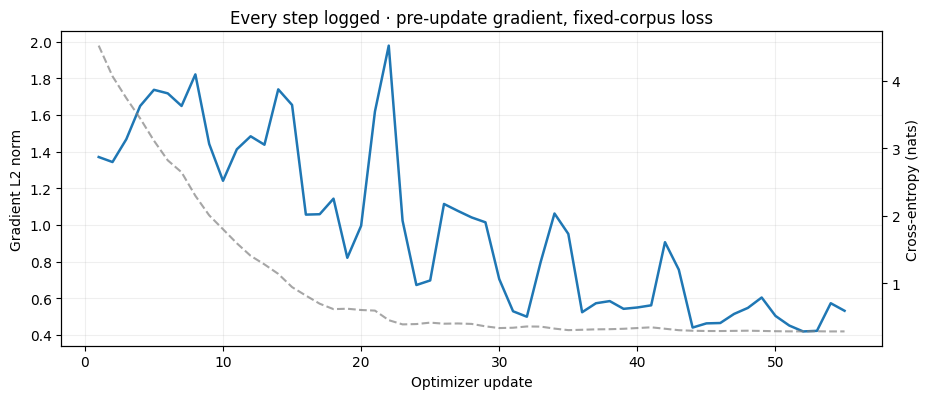

Observed training-run threshold event: {'step': 24, 'ce_delta': 0.004932105541229248, 'gradient_relative_change': 0.3430938369894329}
Controlled probe (same parameter, no update): [{'x': 1.0, 'loss': 1.0, 'grad_norm': 2.0}, {'x': 4.0, 'loss': 1.0, 'grad_norm': 8.0}]
Interpretation: at unchanged loss 1.000000, grad norm changes 2 -> 8. This is a controlled probe, not a measured lead-time forecast.


/tmp/ipykernel_778/1570709222.py:30: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  probe.append({'x':xx,'loss':float(loss),'grad_norm':float(abs(w.grad))})


In [6]:
fig,ax=plt.subplots(figsize=(9.4,4.1))
ax.plot([r['step'] for r in steps_log],[r['correct_grad_norm'] for r in steps_log],label='Pre-update gradient norm',linewidth=1.8)
ax.set(xlabel='Optimizer update',ylabel='Gradient L2 norm',title='Every step logged · pre-update gradient, fixed-corpus loss')
ax2=ax.twinx()
ax2.plot([r['step'] for r in steps_log],[r['correct_loss'] for r in steps_log],color='gray',linestyle='--',alpha=.7,label='Post-update fixed-corpus CE')
ax2.set_ylabel('Cross-entropy (nats)')
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig('gradient_norm_and_loss.png',dpi=160)
plt.show()
# Operational early-signal criterion, not a statistical claim: <=0.005 CE change and >=10% norm change.
found=None
for i in range(1,len(steps_log)):
    a,b=steps_log[i-1],steps_log[i]
    ce_delta=abs(b['correct_loss']-a['correct_loss'])
    rel_grad=abs(b['correct_grad_norm']-a['correct_grad_norm'])/max(abs(a['correct_grad_norm']),1e-12)
    if ce_delta <= .005 and rel_grad >= .10:
        found={'step':b['step'],'ce_delta':ce_delta,'gradient_relative_change':rel_grad}
        break
if found:print('Observed training-run threshold event:',found)
else:print('No training-run step met predeclared CE <=0.005 and norm-change >=10% thresholds; not manufacturing an event.')

# Controlled isocost demonstration: L=(w*x-y)^2 at w=0, y=1, x=1 vs x=4.
# Same monitored scalar loss, different true gradients, with NO optimizer update.
w=torch.tensor(0.,requires_grad=True)
probe=[]
for xx in [1.,4.]:
    w.grad=None
    loss=(w*xx-1.)**2
    loss.backward()
    probe.append({'x':xx,'loss':float(loss),'grad_norm':float(abs(w.grad))})
print('Controlled probe (same parameter, no update):',probe)
assert probe[0]['loss']==probe[1]['loss']==1 and probe[0]['grad_norm']==2 and probe[1]['grad_norm']==8
print('Interpretation: at unchanged loss 1.000000, grad norm changes 2 -> 8. This is a controlled probe, not a measured lead-time forecast.')

## 6 · Measured throughput, and an honest MFU denominator
`6 * N * tokens/sec` is a **rough dense-transformer** arithmetic approximation (non-embedding parameters).
Exact attention FLOPs, sequence length and implementation overhead make it approximate, especially on this tiny model.
**True GPU MFU** requires GPU execution **and** a verified peak dense FLOP/s for the precision actually used.
This reference runs on CPU. It reports useful estimated model FLOP/s, a *CPU matmul-reference proxy* and GPU MFU = N/A.
In Colab on GPU, use the CUDA measurement cell below and explicitly enter the verified vendor GPU peak.

In [7]:
params_all=sum(p.numel() for p in base.parameters())
params_nonemb=sum(p.numel() for n,p in base.named_parameters() if not n.startswith(('tok.','pos.')))
# 6*N typically counts all non-embedding matrix multiplications, including output head in this implementation.
# A small benchmark at a frozen checkpoint avoids conflating training-quality with speed.
bench=copy.deepcopy(base)
opt_bench=torch.optim.SGD(bench.parameters(),lr=0.0)
bench_x=collate([encoded[0],encoded[1],encoded[8],encoded[9]])
valid_per_step=int((bench_x[:,1:]!=PAD).sum())
for _ in range(3):
    opt_bench.zero_grad(set_to_none=True)
    loss=shifted_loss(bench(bench_x),bench_x)[0];loss.backward();opt_bench.step()
iterations=25
start=time.perf_counter()
for _ in range(iterations):
    opt_bench.zero_grad(set_to_none=True)
    loss=shifted_loss(bench(bench_x),bench_x)[0];loss.backward();opt_bench.step()
seconds=time.perf_counter()-start
rate=valid_per_step*iterations/seconds
model_flops_per_sec=6*params_nonemb*rate
print(f'Runtime={platform.platform()} / CPU threads={CPU_THREADS}, measured {iterations} steady-state train updates')
print(f'Parameters: all={params_all:,}; non-embedding/positional={params_nonemb:,}')
print(f'Valid predicted tokens per update={valid_per_step}; elapsed={seconds:.6f}s; useful tokens/s={rate:.3f}')
print(f'Approximate useful model FLOP/s: 6*{params_nonemb}*{rate:.3f} = {model_flops_per_sec:.4e}')
# Optional CPU reference: max of repeated 384x384 fp32 matmuls. This is *NOT hardware theoretical peak*.
a=torch.randn(384,384);b=torch.randn(384,384)
for _ in range(3):torch.mm(a,b)
mm_times=[]
for _ in range(4):
    st=time.perf_counter()
    for j in range(10):torch.mm(a,b)
    mm_times.append(time.perf_counter()-st)
mm_peak=2*(384**3)*10/min(mm_times)
cpu_proxy=model_flops_per_sec/mm_peak
print(f'Local CPU matmul reference (empirical best): {mm_peak/1e9:.3f} GFLOP/s')
print(f'CPU reference ratio (NOT standard GPU MFU): {cpu_proxy*100:.3f}%')
print('GPU MFU: N/A — no CUDA used in this executed reference. 40% GPU comparison is inapplicable.')
print('Plausible efficiency costs, not measured causal attributions: tiny GEMMs, CPU dispatch/Python overhead, attention operations not in 6N, optimizer, and memory traffic.')

Runtime=Linux-6.18.44-x86_64-with-glibc2.41 / CPU threads=2, measured 25 steady-state train updates
Parameters: all=16,672; non-embedding/positional=12,256
Valid predicted tokens per update=42; elapsed=0.029151s; useful tokens/s=36019.109
Approximate useful model FLOP/s: 6*12256*36019.109 = 2.6487e+09
Local CPU matmul reference (empirical best): 195.305 GFLOP/s
CPU reference ratio (NOT standard GPU MFU): 1.356%
GPU MFU: N/A — no CUDA used in this executed reference. 40% GPU comparison is inapplicable.
Plausible efficiency costs, not measured causal attributions: tiny GEMMs, CPU dispatch/Python overhead, attention operations not in 6N, optimizer, and memory traffic.


### Optional Colab GPU MFU (explicitly opt in after checking vendor peak)
The following cell intentionally **refuses** to fabricate a GPU MFU denominator. Set `GPU_PEAK_DENSE_TFLOPS_FP32`
to the published *dense FP32 non-tensor-core peak for the exact GPU SKU*. Our baseline uses FP32 (not FP8/BF16).
Matching the precision and dense/sparse specification matters. Output is N/A until this is supplied.

In [8]:
GPU_PEAK_DENSE_TFLOPS_FP32 = None   # Never infer this value from the word "GPU" alone.
if not torch.cuda.is_available():
    print('Colab GPU benchmark: N/A (CUDA is not available).')
elif GPU_PEAK_DENSE_TFLOPS_FP32 is None:
    print('CUDA detected:',torch.cuda.get_device_name(0))
    print('GPU MFU: N/A until a verified dense FP32 peak TFLOP/s is configured.')
else:
    assert GPU_PEAK_DENSE_TFLOPS_FP32 > 0
    dev=torch.device('cuda')
    gm=copy.deepcopy(base).to(dev)
    gb=bench_x.to(dev)
    optimizer=torch.optim.SGD(gm.parameters(),lr=0.0)
    for _ in range(5):
        optimizer.zero_grad(set_to_none=True)
        z=shifted_loss(gm(gb),gb)[0];z.backward();optimizer.step()
    torch.cuda.synchronize()
    n=30
    start=time.perf_counter()
    for _ in range(n):
        optimizer.zero_grad(set_to_none=True)
        z=shifted_loss(gm(gb),gb)[0];z.backward();optimizer.step()
    torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    gpu_tps=n*valid_per_step/elapsed
    gpu_mfu=6*params_nonemb*gpu_tps/(GPU_PEAK_DENSE_TFLOPS_FP32*1e12)
    print(f'GPU: {torch.cuda.get_device_name(0)} | precision=FP32 | dense peak={GPU_PEAK_DENSE_TFLOPS_FP32} TFLOP/s')
    print(f'Measured GPU tokens/s={gpu_tps:.2f}; approximate GPU MFU={gpu_mfu*100:.5f}%')

Colab GPU benchmark: N/A (CUDA is not available).


## 7 · Encode decimal 0.1 by hand: fp32, bf16, fp8 E4M3FN
`0.1` has a repeating binary expansion. Each format rounds to its nearest representable value.
FP8 here means PyTorch `float8_e4m3fn`, exponent bias 7, **not** E4M3FNUZ and not E5M2.
The code independently checks the bit strings and reconstructed values.

In [9]:
fp32bits=struct.unpack('>I',struct.pack('>f',0.1))[0]
fp32value=struct.unpack('>f',struct.pack('>I',fp32bits))[0]
bf16_round=((fp32bits + 0x7fff + ((fp32bits>>16)&1))>>16)&0xffff
bf16value=struct.unpack('>f',struct.pack('>I',bf16_round<<16))[0]
# Exhaustive nearest finite E4M3FN decoding (simple manual format verifier independent of torch cast).
def e4m3_decode(raw):
    sign=-1 if raw & 0x80 else 1
    exp=(raw >> 3)&0xf
    mant=raw&7
    if exp==15 and mant==7:return float('nan')
    return sign* ((mant/8)*2**(-6) if exp==0 else (1+mant/8)*2**(exp-7))
candidates=[(abs(e4m3_decode(z)-0.1),z) for z in range(256) if math.isfinite(e4m3_decode(z))]
_,fp8bits=min(candidates)
fp8value=e4m3_decode(fp8bits)
assert fp32bits==0x3dcccccd and bf16_round==0x3dcd and fp8bits==0x1d
assert abs(fp8value-0.1015625)<1e-12
# Independent PyTorch conversion check (limited E4M3 operation support; cast is supported here).
try:
    t8=torch.tensor([0.1],dtype=torch.float32).to(torch.float8_e4m3fn)
    torch_f8_bits=int(t8.view(torch.uint8)[0].item())
    assert torch_f8_bits == fp8bits
    print('FP8 check: manual exhaustive encoding agrees with PyTorch cast bit-for-bit.')
except (RuntimeError,NotImplementedError) as e:
    print('PyTorch FP8 cast unsupported on this runtime; manual exhaustive representation remains verified:',str(e)[:150])
print('Decimal 0.1 binary = 0.000110011001100110011… (repeating)')
print('FP32       = sign 0 | exponent 01111011 (123-127=-4) | mantissa 10011001100110011001101')
print(f'             0x{fp32bits:08x} = {fp32value:.17f} | abs error={abs(fp32value-.1):.11g}')
print('BF16       = sign 0 | exponent 01111011 (123-127=-4) | mantissa 1001101')
print(f'             0x{bf16_round:04x} = {bf16value:.17f} | abs error={abs(bf16value-.1):.11g}')
print('FP8 E4M3FN = sign 0 | exponent 0011 (3-7=-4)    | mantissa 101')
print(f'             0x{fp8bits:02x} = {fp8value:.17f} | abs error={abs(fp8value-.1):.11g}')
print('Precision recommendation: BF16 activations/matmuls when GPU supports it, with FP32 optimizer/master state and appropriate accumulation.')
print('This CPU baseline actually trained in FP32; FP8 training requires validated scaling, kernels and hardware — an isolated cast is NOT a training validation.')

FP8 check: manual exhaustive encoding agrees with PyTorch cast bit-for-bit.
Decimal 0.1 binary = 0.000110011001100110011… (repeating)
FP32       = sign 0 | exponent 01111011 (123-127=-4) | mantissa 10011001100110011001101
             0x3dcccccd = 0.10000000149011612 | abs error=1.4901161138e-09
BF16       = sign 0 | exponent 01111011 (123-127=-4) | mantissa 1001101
             0x3dcd = 0.10009765625000000 | abs error=9.765625e-05
FP8 E4M3FN = sign 0 | exponent 0011 (3-7=-4)    | mantissa 101
             0x1d = 0.10156250000000000 | abs error=0.0015625
Precision recommendation: BF16 activations/matmuls when GPU supports it, with FP32 optimizer/master state and appropriate accumulation.
This CPU baseline actually trained in FP32; FP8 training requires validated scaling, kernels and hardware — an isolated cast is NOT a training validation.


## 8 · Auditable export and assertion summary
`results.json` contains measured numbers, environment, threshold criteria, a clear MFU N/A, and the exact format fields.
This output is reproducible to floating-point tolerance; wall-clock throughput varies across runs and Colab hardware.

In [10]:
report = {
 'experiment': 'ERA V5 Session 10 training harness', 'seed':SEED,
 'torch':torch.__version__, 'cpu_threads':CPU_THREADS,'run_device':str(DEVICE),
 'dataset':{'type':'fixed original toy text corpus','documents':len(TEXTS),'vocab':V,'max_length':MAX_T},
 'model':{'all_parameters':params_all,'nonembedding_parameters':params_nonemb,'width':C,'heads':H},
 'gradient':{'autograd':analytical,'finite_difference':numeric,'abs_error':abs_error,'relative_error':relative_error,'epsilon':eps},
 'accumulation':{'short_targets':s_count,'long_targets':l_count,'full_batch_vs_correct_grad_maxdiff':correct_error,'full_batch_vs_wrong_grad_maxdiff':wrong_error,
                 'first_post_step_correct_loss':steps_log[0]['correct_loss'],'first_post_step_wrong_loss':steps_log[0]['wrong_loss'],
                 'final_correct_loss':steps_log[-1]['correct_loss'],'final_wrong_loss':steps_log[-1]['wrong_loss']},
 'gradient_trace':{'steps_logged':len(steps_log),'event_rule':'abs(fixed_loss_delta) <= 0.005 and rel(gradnorm_delta) >= 0.10','observed_threshold_event':found,'controlled_probe':probe},
 'compute':{'runtime':'CPU FP32','benchmark_iterations':iterations,'seconds':seconds,'valid_tokens_per_step':valid_per_step,'tokens_per_second':rate,
            'estimated_useful_model_flops_per_second_6N':model_flops_per_sec,'empirical_cpu_matmul_reference_flops_per_second':mm_peak,
            'experimental_cpu_reference_utilization_ratio_NOT_MFU':cpu_proxy,'gpu_mfu':None,'gpu_mfu_reason':'Reference executed on CPU; no applicable vendor GPU peak.'},
 'representations':{'fp32':{'bits':format(fp32bits,'032b'),'hex':hex(fp32bits),'value':fp32value},
                    'bf16':{'bits':format(bf16_round,'016b'),'hex':hex(bf16_round),'value':bf16value},
                    'fp8_e4m3fn':{'bits':format(fp8bits,'08b'),'hex':hex(fp8bits),'value':fp8value}},
 'steps':steps_log,
}
Path('results.json').write_text(json.dumps(report,indent=2))
assert math.isfinite(steps_log[-1]['correct_loss']) and math.isfinite(steps_log[-1]['wrong_loss'])
assert len(steps_log)==STEPS
print('ALL ASSERTIONS PASSED. Wrote results.json, accumulation_loss_curves.png and gradient_norm_and_loss.png')

ALL ASSERTIONS PASSED. Wrote results.json, accumulation_loss_curves.png and gradient_norm_and_loss.png
